# Detecção de outliers em licitações com Isolation Forest

**Objetivo:** identificar registros atípicos (possíveis indícios de fraude ou erro de cadastro) no dataset `licitacoes_tratados.xlsx` usando o algoritmo não supervisionado **Isolation Forest**.


1. Carga dos dados e remoção das colunas `outlier_valor_proposta` e `variacao_pct`
2. Pré-processamento e engenharia de atributos
3. Escolha de hiperparâmetros (sem rótulos): estabilidade + validação com anomalias sintéticas
4. Treino do modelo final
5. Análise e interpretação dos outliers
6. Exportação dos resultados

> **Importante:** um outlier é apenas um registro *estatisticamente diferente* dos demais. Isso **não** prova fraude. O resultado deve ser usado para *priorizar* registros para auditoria humana.

## 1. Imports e configurações

In [2]:
import warnings, itertools, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.stats import spearmanr
from sklearn.ensemble import IsolationForest
from sklearn.metrics import roc_auc_score, average_precision_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 60)

# ---------------- CONFIGURAÇÕES (altere aqui) ----------------
ARQUIVO = "licitacoes_tratados.xlsx"   # no Colab: faça upload do arquivo antes
RANDOM_STATE = 42

# True  -> usa só linhas que têm valor_proposta (48% das linhas não têm proposta)
# False -> usa todas as linhas (valores ausentes são imputados pela mediana)
SOMENTE_COM_PROPOSTA = False

# "frequencia" -> 1 coluna por variável categórica (log da frequência da categoria)
# "onehot"     -> one-hot (categorias com <1% viram "Outros")
CODIFICACAO_CATEGORICAS = "frequencia"

# Se True, cria colunas 0/1 indicando valor ausente. Cuidado: isso faz o modelo
# destacar registros por *padrão de preenchimento* e não por *valores*.
INCLUIR_INDICADORES_AUSENCIA = False

# Fração de registros que será marcada como outlier no resultado final
PERCENTUAL_OUTLIERS = 0.01

## 2. Carga dos dados e remoção das duas últimas colunas
As colunas `outlier_valor_proposta` e `variacao_pct` são **descartadas** antes de qualquer tratamento, conforme solicitado.

In [3]:
df_raw = pd.read_excel(ARQUIVO)
print("Shape original:", df_raw.shape)

COLS_EXCLUIR = ["outlier_valor_proposta", "variacao_pct"]
assert list(df_raw.columns[-2:]) == COLS_EXCLUIR, "As duas últimas colunas não são as esperadas!"

df = df_raw.drop(columns=COLS_EXCLUIR).copy()
print("Shape após remover as 2 últimas colunas:", df.shape)
df.head()

Shape original: (51065, 23)
Shape após remover as 2 últimas colunas: (51065, 21)


,municipio,entidade,codigo_licitacao,modalidade,objeto,descricao_objeto,produto_item,qtd_contratada_item,unidade_objeto_contratado,valor_unit_orcado_lote,qtd_orcada_lote,unidade_lote,valor_unit_orcado_item,qtd_orcada_item,unidade_item,numero_edital,data_edital,cnpj_participante,nome_participante,resultado_habilitacao,valor_proposta
0,Andradina,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE A...,2025000000002,Pregao Eletronico,Generos alimenticios,Kit lanche participação exclusiva ME EPP,Kit lanche nº 2,1250.0,NaN,NaN,NaN,NaN,18.5,1250.0,kit,900015,2025-08-06,14.564.689/0001-91,P Q SANTOS BUFFET,Classificado - Vencedor,40687500.0
1,Andradina,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE A...,2025000000002,Pregao Eletronico,Generos alimenticios,Kit lanche participação exclusiva ME EPP,Kit lanche nº 2,1250.0,NaN,NaN,NaN,NaN,18.5,1250.0,kit,900015,2025-08-06,18.469.456/0001-60,DOLLETO DOCES E SALGADOS LTDA,Classificado,41037500.0
2,Andradina,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE A...,2025000000002,Pregao Eletronico,Generos alimenticios,Kit lanche participação exclusiva ME EPP,Kit lanche nº 2,1250.0,NaN,NaN,NaN,NaN,35.0,1250.0,kit,900015,2025-08-06,14.564.689/0001-91,P Q SANTOS BUFFET,Classificado - Vencedor,40687500.0
3,Andradina,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE A...,2025000000002,Pregao Eletronico,Generos alimenticios,Kit lanche participação exclusiva ME EPP,Kit lanche nº 2,1250.0,NaN,NaN,NaN,NaN,35.0,1250.0,kit,900015,2025-08-06,18.469.456/0001-60,DOLLETO DOCES E SALGADOS LTDA,Classificado,41037500.0
4,Andradina,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE A...,2025000000002,Pregao Eletronico,Generos alimenticios,Kit lanche participação exclusiva ME EPP,Kit lanche nº 2,1250.0,NaN,NaN,NaN,NaN,43.5,1250.0,kit,900015,2025-08-06,14.564.689/0001-91,P Q SANTOS BUFFET,Classificado - Vencedor,40687500.0


### 2.1 Visão geral: tipos e valores ausentes

In [4]:
resumo = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "n_ausentes": df.isna().sum(),
    "%_ausentes": (df.isna().mean() * 100).round(1),
    "n_unicos": df.nunique(),
}).sort_values("%_ausentes", ascending=False)
resumo

,tipo,n_ausentes,%_ausentes,n_unicos
unidade_objeto_contratado,float64,51065,100.0,0
qtd_orcada_item,float64,30233,59.2,205
unidade_item,object,30233,59.2,115
valor_unit_orcado_item,float64,30233,59.2,4417
qtd_contratada_item,float64,29826,58.4,229
produto_item,object,29826,58.4,2919
valor_proposta,float64,24812,48.6,4999
cnpj_participante,object,24510,48.0,1165
nome_participante,object,24467,47.9,1286
resultado_habilitacao,object,24461,47.9,7


## 3. Pré-processamento

Decisões tomadas (e por quê):

| Decisão | Motivo |
|---|---|
| Remover `unidade_objeto_contratado` | 100% vazia |
| Remover identificadores e textos livres (`codigo_licitacao`, `numero_edital`, `cnpj_participante`, `nome_participante`, `descricao_objeto`, `produto_item`, `unidade_*`) | Alta cardinalidade; um ID não tem "distância" significativa e geraria ruído |
| `log1p` nas variáveis numéricas | Valores vão de centavos a centenas de milhões. O Isolation Forest sorteia cortes **uniformemente entre mín. e máx.**; sem log, quase tudo ficaria "espremido" perto de zero e só os extremos absolutos seriam isolados |
| Imputar ausentes pela mediana | O sklearn não precisa de NaN; a mediana é neutra (não torna o registro artificialmente raro) |
| Não usar `municipio` nem `entidade` como atributos | Municípios/entidades com poucas linhas seriam considerados "raros" e **100% das suas linhas** viraria outlier (efeito de frequência, não de valor). Eles são usados apenas na análise dos resultados |
| Corrigir *mojibake* (ex.: `ÃÂ³` → `ó`) e agrupar `modalidade` | Há 24 grafias para ~8 modalidades; sem agrupar, variantes de digitação virariam "categorias raras" |

In [5]:
# --- 3.1 Correção de texto com codificação quebrada (mojibake) ---
def corrige_texto(s):
    if not isinstance(s, str):
        return s
    for _ in range(2):
        if any(ch in s for ch in "ÃÂ"):
            try:
                s = s.encode("latin-1").decode("utf-8")
            except (UnicodeEncodeError, UnicodeDecodeError):
                break
    return s

for c in df.columns:
    if pd.api.types.is_string_dtype(df[c]) or df[c].dtype == object:
        mapa = {u: corrige_texto(u) for u in df[c].dropna().unique()}
        df[c] = df[c].map(mapa)

# --- 3.2 Agrupamento das modalidades ---
def normaliza(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper()

def grupo_modalidade(m):
    if not isinstance(m, str):
        return "Ausente"
    t = normaliza(m)
    if "PREGAO" in t:            return "Pregão"
    if "CONCORRENCIA" in t:      return "Concorrência"
    if "CONVITE" in t:           return "Convite"
    if "INEXIGIBILIDADE" in t:   return "Inexigibilidade"
    if "DISPENSA" in t:          return "Dispensa"
    if "COMPRA DIRETA" in t:     return "Compra direta (FAEPA)"
    if any(k in t for k in ("COLETA", "COTACAO", "ORCAMENTO")):
        return "Cotação / coleta de preços"
    return "Outros (regulamento FAEPA)"

df["modalidade_grupo"] = df["modalidade"].map(grupo_modalidade)
display(pd.crosstab(df["modalidade_grupo"], df["modalidade"].isna(), margins=True))
df["modalidade_grupo"].value_counts()

modalidade,False,True,All
modalidade_grupo,,,
Ausente,0,1,1
Compra direta (FAEPA),12302,0,12302
Concorrência,192,0,192
Convite,157,0,157
Cotação / coleta de preços,948,0,948
Dispensa,8501,0,8501
Inexigibilidade,334,0,334
Outros (regulamento FAEPA),50,0,50
Pregão,28580,0,28580


modalidade_grupo
Pregão                        28580
Compra direta (FAEPA)         12302
Dispensa                       8501
Cotação / coleta de preços      948
Inexigibilidade                 334
Concorrência                    192
Convite                         157
Outros (regulamento FAEPA)       50
Ausente                           1
Name: count, dtype: int64

In [6]:
# --- 3.3 Seleção de colunas ---
COLS_NUM = [
    "qtd_contratada_item", "valor_unit_orcado_lote", "qtd_orcada_lote",
    "valor_unit_orcado_item", "qtd_orcada_item", "valor_proposta",
]
# municipio e entidade ficam FORA dos atributos: municípios/entidades pequenos viram "raros"
# e o modelo marcaria 100% das suas linhas como outlier (artefato de frequência, não de valor).
# Eles continuam disponíveis na análise dos resultados (seção 6).
COLS_CAT = ["modalidade_grupo", "objeto", "resultado_habilitacao"]

if SOMENTE_COM_PROPOSTA:
    df = df[df["valor_proposta"].notna()].copy()
print("Linhas usadas:", len(df))

def codificar_categoricas(df, cols, modo):
    if modo == "frequencia":
        out = pd.DataFrame(index=df.index)
        for c in cols:
            s = df[c].fillna("Ausente").astype(str)
            out[f"logfreq_{c}"] = np.log(s.map(s.value_counts(normalize=True)))
        return out
    partes = []
    for c in cols:
        s = df[c].fillna("Ausente").astype(str)
        raras = s.value_counts(normalize=True)
        raras = raras[raras < 0.01].index
        s = s.where(~s.isin(raras), "Outros")
        partes.append(pd.get_dummies(s, prefix=c, dtype=float))
    return pd.concat(partes, axis=1)

def construir_features(df):
    X = pd.DataFrame(index=df.index)
    X_log_raw = pd.DataFrame(index=df.index)        # log com NaN (para interpretação)
    for c in COLS_NUM:
        v = np.log1p(df[c].astype(float).clip(lower=0))
        X_log_raw[f"log_{c}"] = v
        X[f"log_{c}"] = v.fillna(v.median())
        if INCLUIR_INDICADORES_AUSENCIA:
            X[f"ausente_{c}"] = df[c].isna().astype(float)
    dias = (df["data_edital"] - df["data_edital"].min()).dt.days.astype(float)
    X["data_edital_dias"] = dias.fillna(dias.median())
    X = pd.concat([X, codificar_categoricas(df, COLS_CAT, CODIFICACAO_CATEGORICAS)], axis=1)
    X = X.loc[:, X.nunique() > 1]                    # remove colunas constantes
    return X, X_log_raw

X, X_log_raw = construir_features(df)
print("Matriz de atributos:", X.shape)
print("Atributos:", list(X.columns))
assert not X.isna().any().any()
X.describe().T[["mean", "std", "min", "50%", "max"]].round(2)

Linhas usadas: 51065
Matriz de atributos: (51065, 10)
Atributos: ['log_qtd_contratada_item', 'log_valor_unit_orcado_lote', 'log_qtd_orcada_lote', 'log_valor_unit_orcado_item', 'log_qtd_orcada_item', 'log_valor_proposta', 'data_edital_dias', 'logfreq_modalidade_grupo', 'logfreq_objeto', 'logfreq_resultado_habilitacao']


,mean,std,min,50%,max
log_qtd_contratada_item,2.50,1.16,0.25,2.40,15.16
log_valor_unit_orcado_lote,4.04,2.64,0.00,3.50,19.13
log_qtd_orcada_lote,3.50,1.82,0.00,3.40,13.31
log_valor_unit_orcado_item,5.35,1.59,0.02,5.25,14.95
log_qtd_orcada_item,2.47,1.12,0.00,2.40,15.16
log_valor_proposta,6.78,2.85,0.00,6.86,19.19
data_edital_dias,882.25,92.10,0.00,899.00,1011.00
logfreq_modalidade_grupo,-1.12,0.83,-10.84,-0.58,-0.58
logfreq_objeto,-1.91,0.73,-10.84,-1.81,-1.40
logfreq_resultado_habilitacao,-1.44,0.84,-6.78,-1.62,-0.74


## 4. Escolha dos hiperparâmetros

Como **não temos rótulos** (não sabemos quais registros são fraude), não dá para usar *accuracy*, F1 etc. Usamos duas evidências complementares:

1. **Estabilidade** – um bom modelo dá praticamente o mesmo ranking de anomalias com sementes aleatórias diferentes (correlação de Spearman entre execuções e sobreposição do top 1%).
2. **Anomalias sintéticas** – injetamos ~1% de registros artificiais (valores reais multiplicados por 10–200×) e medimos o quanto cada configuração os encontra (ROC-AUC e Average Precision). O modelo **não** vê esse rótulo.

**O que cada hiperparâmetro faz**

| Hiperparâmetro | Efeito | Como escolher |
|---|---|---|
| `n_estimators` | Nº de árvores. Mais árvores = scores mais estáveis | Aumentar até a estabilidade parar de melhorar (seção 4.1) |
| `max_samples` | Nº de linhas por árvore. Poucas → árvores rasas e rápidas, mas pode ignorar padrões de grupos pequenos; muitas → risco de *masking* (clusters de outliers se "protegem") | Testar 256, 1024, 4096… (seção 4.2) |
| `max_features` | Fração de atributos por árvore. Menor = mais diversidade, ajuda com muitos atributos correlacionados | Testar 0.5 – 1.0 (seção 4.2) |
| `contamination` | **Não altera os scores**, apenas o ponto de corte (limiar) | Definido pelo critério de negócio, ex.: "quantos registros consigo auditar?" (seção 5) |

### 4.1 Quantas árvores são suficientes? (convergência dos scores)

,n_estimators,spearman_entre_sementes
0,10,0.826529
1,25,0.918922
2,50,0.944375
3,100,0.971967
4,200,0.985099
5,400,0.992126
6,800,0.997021


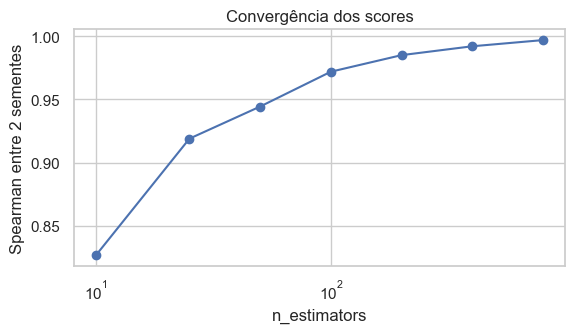

In [7]:
def score_if(X, seed, **params):
    m = IsolationForest(random_state=seed, n_jobs=-1, **params).fit(X)
    return -m.score_samples(X)          # quanto MAIOR, mais anômalo

lista_n = [10, 25, 50, 100, 200, 400, 800]
conv = []
for n in lista_n:
    a = score_if(X, 1, n_estimators=n, max_samples=256)
    b = score_if(X, 2, n_estimators=n, max_samples=256)
    conv.append({"n_estimators": n, "spearman_entre_sementes": spearmanr(a, b)[0]})
conv = pd.DataFrame(conv)
display(conv)

plt.figure(figsize=(6, 3.5))
plt.plot(conv["n_estimators"], conv["spearman_entre_sementes"], marker="o")
plt.xscale("log"); plt.xlabel("n_estimators"); plt.ylabel("Spearman entre 2 sementes")
plt.title("Convergência dos scores"); plt.tight_layout(); plt.show()

### 4.2 Grade de busca: estabilidade + anomalias sintéticas
Geramos anomalias artificiais **no espaço de atributos** (em escala log, somando `log(fator)`, fator ∈ [10, 200]) em 1 a 3 colunas numéricas realmente observadas de linhas escolhidas ao acaso.

In [9]:
def gerar_anomalias_sinteticas(X, X_log_raw, n_anom, seed):
    rng = np.random.default_rng(seed)
    cols_log = [c for c in X.columns if c.startswith("log_") and c in X_log_raw.columns]
    idx_cols = [X.columns.get_loc(c) for c in cols_log]
    obs = X_log_raw[cols_log].notna().to_numpy()
    candidatas = np.where(obs.any(axis=1))[0]
    linhas = rng.choice(candidatas, size=n_anom, replace=False)
    Xs = X.iloc[linhas].to_numpy(copy=True)
    for i, r in enumerate(linhas):
        disponiveis = np.where(obs[r])[0]
        k = rng.integers(1, min(3, len(disponiveis)) + 1)
        escolhidas = rng.choice(disponiveis, size=k, replace=False)
        for j in escolhidas:
            Xs[i, idx_cols[j]] += np.log(rng.uniform(10, 200))
    return pd.DataFrame(Xs, columns=X.columns)

N_SINT = int(0.01 * len(X))
X_sint = gerar_anomalias_sinteticas(X, X_log_raw, N_SINT, RANDOM_STATE)
X_aug = pd.concat([X.reset_index(drop=True), X_sint], ignore_index=True)
y_sint = np.r_[np.zeros(len(X)), np.ones(len(X_sint))]
n_real = len(X)
print(f"{n_real} linhas reais + {len(X_sint)} anomalias sintéticas")

51065 linhas reais + 510 anomalias sintéticas


In [10]:
def jaccard_topk(a, b, frac=0.01):
    k = max(1, int(len(a) * frac))
    ta, tb = set(np.argsort(-a)[:k]), set(np.argsort(-b)[:k])
    return len(ta & tb) / len(ta | tb)

def avaliar_config(params, seeds=(0, 1, 2)):
    scores = []
    aucs, aps = [], []
    for s in seeds:
        sc = score_if(X_aug, s, **params)
        scores.append(sc)
        aucs.append(roc_auc_score(y_sint, sc))
        aps.append(average_precision_score(y_sint, sc))
    reais = [s[:n_real] for s in scores]                   # estabilidade só nas linhas reais
    pares = list(itertools.combinations(range(len(seeds)), 2))
    return {
        **params,
        "auc_sintetico": np.mean(aucs),
        "ap_sintetico": np.mean(aps),
        "estabilidade_spearman": np.mean([spearmanr(reais[i], reais[j])[0] for i, j in pares]),
        "estabilidade_top1pct": np.mean([jaccard_topk(reais[i], reais[j]) for i, j in pares]),
    }

grade = {
    "n_estimators": [100, 300],
    "max_samples": [256, 1024, 4096, 16384, 32768],
    "max_features": [0.5, 0.75, 1.0],
}
configs = [dict(zip(grade, v)) for v in itertools.product(*grade.values())]
print(len(configs), "configurações x 3 sementes")

resultados = []
for i, p in enumerate(configs, 1):
    resultados.append(avaliar_config(p))
    print(f"[{i}/{len(configs)}] {p}")
res = pd.DataFrame(resultados)
res.sort_values("ap_sintetico", ascending=False).round(4)

30 configurações x 3 sementes
[1/30] {'n_estimators': 100, 'max_samples': 256, 'max_features': 0.5}
[2/30] {'n_estimators': 100, 'max_samples': 256, 'max_features': 0.75}
[3/30] {'n_estimators': 100, 'max_samples': 256, 'max_features': 1.0}
[4/30] {'n_estimators': 100, 'max_samples': 1024, 'max_features': 0.5}
[5/30] {'n_estimators': 100, 'max_samples': 1024, 'max_features': 0.75}
[6/30] {'n_estimators': 100, 'max_samples': 1024, 'max_features': 1.0}
[7/30] {'n_estimators': 100, 'max_samples': 4096, 'max_features': 0.5}
[8/30] {'n_estimators': 100, 'max_samples': 4096, 'max_features': 0.75}
[9/30] {'n_estimators': 100, 'max_samples': 4096, 'max_features': 1.0}
[10/30] {'n_estimators': 100, 'max_samples': 16384, 'max_features': 0.5}
[11/30] {'n_estimators': 100, 'max_samples': 16384, 'max_features': 0.75}
[12/30] {'n_estimators': 100, 'max_samples': 16384, 'max_features': 1.0}
[13/30] {'n_estimators': 100, 'max_samples': 32768, 'max_features': 0.5}
[14/30] {'n_estimators': 100, 'max_sam

,n_estimators,max_samples,max_features,auc_sintetico,ap_sintetico,estabilidade_spearman,estabilidade_top1pct
29,300,32768,1.00,0.8461,0.0662,0.9879,0.8545
14,100,32768,1.00,0.8423,0.0661,0.9689,0.7864
28,300,32768,0.75,0.8382,0.0616,0.9882,0.8591
13,100,32768,0.75,0.8294,0.0599,0.9644,0.7393
12,100,32768,0.50,0.8282,0.0579,0.9449,0.7402
27,300,32768,0.50,0.8314,0.0568,0.9873,0.7993
26,300,16384,1.00,0.8395,0.0547,0.9909,0.8402
11,100,16384,1.00,0.8401,0.0539,0.9727,0.7928
25,300,16384,0.75,0.8332,0.0534,0.9873,0.8558
10,100,16384,0.75,0.8296,0.0533,0.9646,0.7052


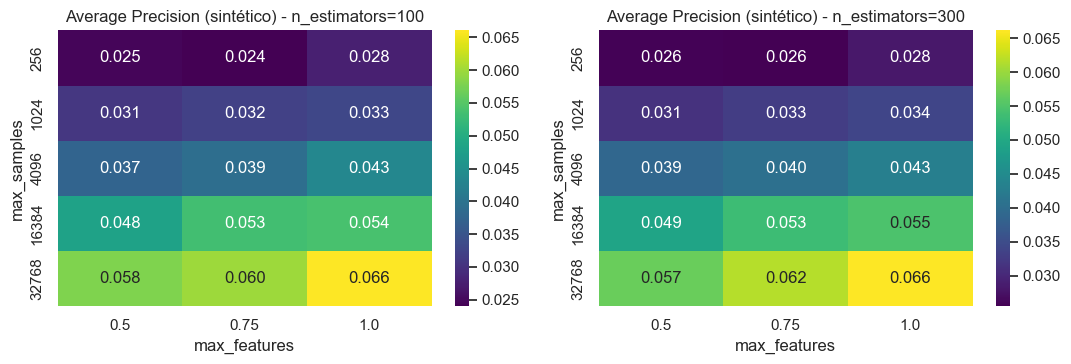

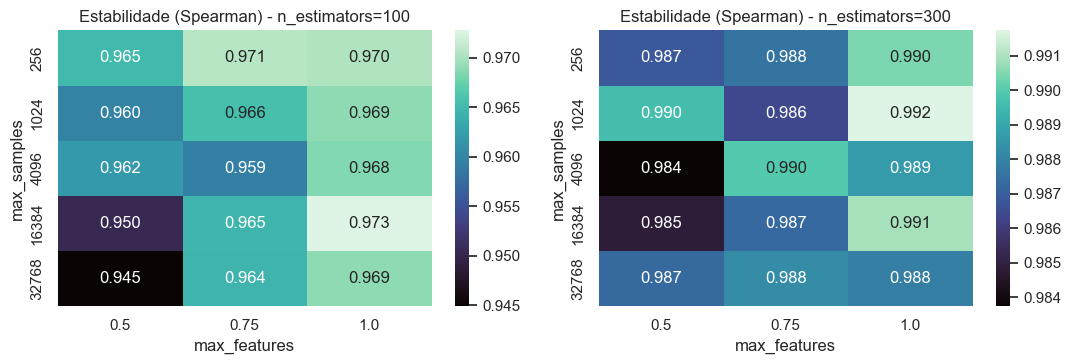

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(axes, grade["n_estimators"]):
    piv = (res[res.n_estimators == n]
           .pivot(index="max_samples", columns="max_features", values="ap_sintetico"))
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="viridis", ax=ax)
    ax.set_title(f"Average Precision (sintético) - n_estimators={n}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, n in zip(axes, grade["n_estimators"]):
    piv = (res[res.n_estimators == n]
           .pivot(index="max_samples", columns="max_features", values="estabilidade_spearman"))
    sns.heatmap(piv, annot=True, fmt=".3f", cmap="mako", ax=ax)
    ax.set_title(f"Estabilidade (Spearman) - n_estimators={n}")
plt.tight_layout(); plt.show()

### 4.3 Regra de seleção
1. Mantemos apenas as configurações **estáveis**: correlação de Spearman entre sementes ≥ 0,98.
2. Entre elas, escolhemos a de maior *Average Precision* nas anomalias sintéticas (desempate por ROC-AUC).

> Se a melhor configuração estiver na **borda** da grade (ex.: o maior `max_samples` testado), amplie a grade nessa direção e rode novamente.

In [12]:
LIMITE_ESTABILIDADE = 0.98
elegiveis = res[res.estabilidade_spearman >= LIMITE_ESTABILIDADE]
if elegiveis.empty:
    print("Nenhuma config atingiu o limite; considerando todas as configurações.")
    elegiveis = res

melhor = elegiveis.sort_values(["ap_sintetico", "auc_sintetico"], ascending=False).iloc[0]

MELHORES_PARAMS = {
    "n_estimators": int(melhor["n_estimators"]),
    "max_samples": int(melhor["max_samples"]),
    "max_features": float(melhor["max_features"]),
}
print("Hiperparâmetros escolhidos:", MELHORES_PARAMS)
melhor.to_frame("valor").T

Hiperparâmetros escolhidos: {'n_estimators': 300, 'max_samples': 32768, 'max_features': 1.0}


,n_estimators,max_samples,max_features,auc_sintetico,ap_sintetico,estabilidade_spearman,estabilidade_top1pct
valor,300.0,32768.0,1.0,0.846116,0.066159,0.987858,0.85455


## 5. Modelo final e definição do limiar (`contamination`)
O modelo final é treinado **somente nos dados reais** (sem as anomalias sintéticas). Como o `contamination` só define o corte, ajustamos com `"auto"` e escolhemos o limiar por percentil, olhando a distribuição dos scores.

Limiar (percentil 99.0): 0.5500
Outliers marcados: 511 de 51065


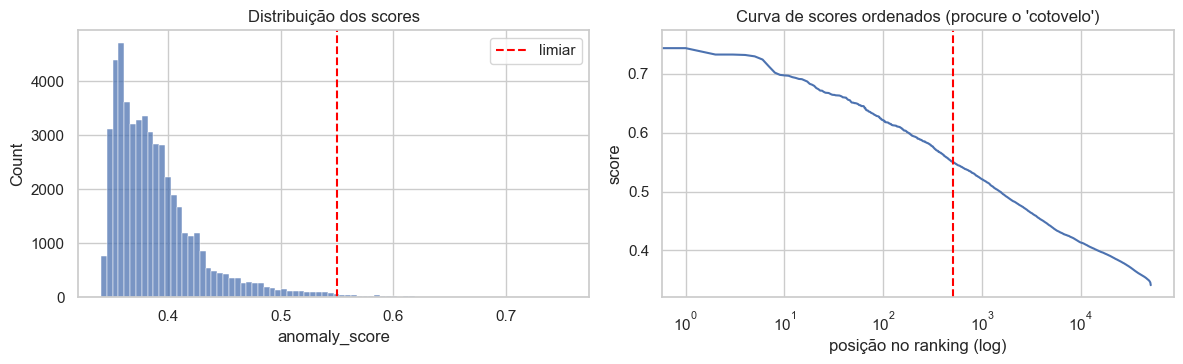

,% marcado,n_registros,score_limiar
0,0.005,255,0.585169
1,0.010,510,0.550024
2,0.020,1021,0.519875
3,0.050,2553,0.474327


In [13]:
modelo = IsolationForest(
    **MELHORES_PARAMS, contamination="auto", random_state=RANDOM_STATE, n_jobs=-1
).fit(X)

df_res = df.copy()
df_res["anomaly_score"] = -modelo.score_samples(X)     # maior = mais anômalo (~0.5 normal, >0.6 suspeito)
limiar = df_res["anomaly_score"].quantile(1 - PERCENTUAL_OUTLIERS)
df_res["outlier"] = df_res["anomaly_score"] >= limiar
df_res["ranking"] = df_res["anomaly_score"].rank(ascending=False, method="first").astype(int)

print(f"Limiar (percentil {100*(1-PERCENTUAL_OUTLIERS):.1f}): {limiar:.4f}")
print(f"Outliers marcados: {df_res['outlier'].sum()} de {len(df_res)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
sns.histplot(df_res["anomaly_score"], bins=80, ax=axes[0])
axes[0].axvline(limiar, color="red", ls="--", label="limiar"); axes[0].legend()
axes[0].set_title("Distribuição dos scores")
axes[1].plot(np.sort(df_res["anomaly_score"].to_numpy())[::-1])
axes[1].axvline(PERCENTUAL_OUTLIERS * len(df_res), color="red", ls="--")
axes[1].set_xscale("log"); axes[1].set_xlabel("posição no ranking (log)")
axes[1].set_ylabel("score"); axes[1].set_title("Curva de scores ordenados (procure o 'cotovelo')")
plt.tight_layout(); plt.show()

sens = pd.DataFrame({
    "% marcado": [0.005, 0.01, 0.02, 0.05],
}).assign(
    n_registros=lambda d: (d["% marcado"] * len(df_res)).astype(int),
    score_limiar=lambda d: [df_res["anomaly_score"].quantile(1 - p) for p in d["% marcado"]],
)
sens

## 6. Interpretação dos outliers
O Isolation Forest não explica *por que* um registro é anômalo. Como aproximação, calculamos o **z-score robusto** (mediana e MAD, em escala log) de cada atributo numérico observado e indicamos qual foi o mais extremo.

In [14]:
def z_robusto(serie):
    med = serie.median()
    mad = (serie - med).abs().median() * 1.4826
    if not mad or np.isnan(mad):
        mad = serie.std()
    return (serie - med) / mad

Z = X_log_raw.apply(z_robusto)                         # NaN permanece NaN
Z_abs = Z.abs()
sem_valor = Z_abs.isna().all(axis=1)                   # linhas sem nenhum valor numérico observado
df_res["feature_mais_atipica"] = (Z_abs.fillna(-1).idxmax(axis=1)
                                  .str.replace("log_", "", regex=False)
                                  .where(~sem_valor))
df_res["z_robusto_da_feature"] = [Z.loc[i, "log_" + f] if isinstance(f, str) else np.nan
                                  for i, f in zip(df_res.index, df_res["feature_mais_atipica"])]

cols_exibir = ["ranking", "anomaly_score", "municipio", "entidade", "modalidade_grupo", "objeto",
               "produto_item", "nome_participante", "valor_unit_orcado_item", "qtd_orcada_item",
               "valor_proposta", "feature_mais_atipica", "z_robusto_da_feature"]
top = df_res.sort_values("ranking").head(30)[cols_exibir]
top.round(3)

,ranking,anomaly_score,municipio,entidade,modalidade_grupo,objeto,produto_item,nome_participante,valor_unit_orcado_item,qtd_orcada_item,valor_proposta,feature_mais_atipica,z_robusto_da_feature
44795,1,0.753,Registro,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE R...,Pregão,Servicos de TI,CHAMADAS LOCAIS FIXO/FIXO,TELEFONICA BRASIL S/A,0.150,18692.0,198381.0,qtd_contratada_item,4.231
13160,2,0.743,São Manuel,INSTITUTO MUNICIPAL DE ENSINO SUPERIOR,Concorrência,Concessao de servico publico,NaN,FUNDACAO CULT EDUC DE RADIO E TELEVISAO LANHOSO DE LIMA,NaN,NaN,0.0,valor_proposta,-1.950
44793,3,0.732,Registro,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE R...,Pregão,Servicos de TI,CHAMADAS INTRAESTADUAIS FIXO/FIXO,TELEFONICA BRASIL S/A,0.600,5227.0,198381.0,qtd_contratada_item,3.507
13725,4,0.732,Taubaté,UNIVERSIDADE DE TAUBATE,Pregão,Outros materiais de consumo,SABONETE COSMÉTICO COM EMOLIENTES PARA LIMPEZA DAS,SANTOS HEALTH E SAFETY COMÉRCIO IMPORTAÇÃO E SERVIÇOS LT...,0.090,3840000.0,230400.0,qtd_contratada_item,7.261
13723,5,0.732,Taubaté,UNIVERSIDADE DE TAUBATE,Pregão,Outros materiais de consumo,SABONETE COSMÉTICO COM EMOLIENTES PARA LIMPEZA DAS,SANTOS HEALTH E SAFETY COMÉRCIO IMPORTAÇÃO E SERVIÇOS LT...,0.020,3840000.0,230400.0,qtd_contratada_item,7.261
13724,6,0.729,Taubaté,UNIVERSIDADE DE TAUBATE,Pregão,Outros materiais de consumo,SABONETE COSMÉTICO COM EMOLIENTES PARA LIMPEZA DAS,SANTOS HEALTH E SAFETY COMÉRCIO IMPORTAÇÃO E SERVIÇOS LT...,0.040,3840000.0,230400.0,qtd_contratada_item,7.261
44796,7,0.724,Registro,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE R...,Pregão,Servicos de TI,CHAMADAS LOCAIS FIXO/MÓVEL,TELEFONICA BRASIL S/A,0.900,2920.0,198381.0,valor_unit_orcado_lote,3.192
5863,8,0.712,São Paulo,UNIVERSIDADE DE SAO PAULO / USP-FACULDADE DE ARQUITETURA...,Pregão,Material Escolar,Compasso escolar,CAM SILVERIO COM. DE ARTIGOS PARA ESCRITORIOS LTDA.,0.134,245.0,32928.0,valor_unit_orcado_item,-1.868
44794,9,0.702,Registro,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE R...,Pregão,Servicos de TI,CHAMADAS INTRAESTADUAIS FIXO/MÓVEL,TELEFONICA BRASIL S/A,1.150,228.0,198381.0,valor_unit_orcado_lote,3.192
44791,10,0.698,Registro,SECRETARIA DA EDUCACAO / UNIDADE REGIONAL DE ENSINO DE R...,Pregão,Servicos de TI,CHAMADAS INTERESTADUAIS FIXO/FIXO,TELEFONICA BRASIL S/A,0.800,136.0,198381.0,valor_unit_orcado_lote,3.192


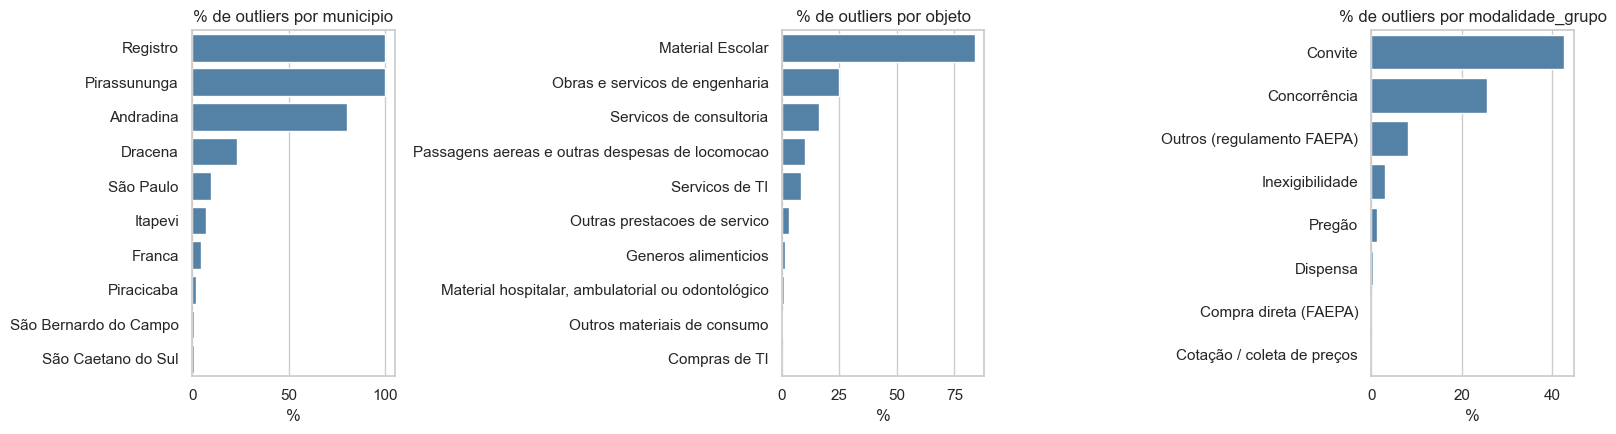

,n,outliers,taxa_pct
municipio,,,
Registro,30,30,100.000000
Pirassununga,51,51,100.000000
Andradina,30,24,80.000000
Dracena,52,12,23.076923
São Paulo,1355,134,9.889299
Itapevi,128,9,7.031250
Franca,420,19,4.523810
Piracicaba,108,2,1.851852
São Bernardo do Campo,234,2,0.854701


In [15]:
def taxa_por(col, minimo=30):
    t = (df_res.groupby(col)
               .agg(n=("outlier", "size"), outliers=("outlier", "sum"))
               .assign(taxa_pct=lambda d: 100 * d["outliers"] / d["n"]))
    return t[t["n"] >= minimo].sort_values("taxa_pct", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ["municipio", "objeto", "modalidade_grupo"]):
    t = taxa_por(col).head(10)
    sns.barplot(x=t["taxa_pct"], y=t.index, ax=ax, color="steelblue")
    ax.set_title(f"% de outliers por {col}"); ax.set_xlabel("%"); ax.set_ylabel("")
plt.tight_layout(); plt.show()

taxa_por("municipio")

In [16]:
# Atributos mais atípicos entre os outliers marcados
(df_res.loc[df_res["outlier"], "feature_mais_atipica"]
       .value_counts().rename("n_outliers").to_frame())

,n_outliers
feature_mais_atipica,
qtd_contratada_item,211
valor_unit_orcado_lote,173
valor_proposta,55
qtd_orcada_lote,47
valor_unit_orcado_item,23
qtd_orcada_item,1


## 7. Exportação dos resultados

In [17]:
cols_saida = [c for c in df_res.columns if c not in ("feature_mais_atipica", "z_robusto_da_feature")] \
             + ["feature_mais_atipica", "z_robusto_da_feature"]
cols_saida = list(dict.fromkeys(cols_saida))

df_res[cols_saida].sort_values("ranking").to_csv("resultados_isolation_forest_completo.csv", index=False)
df_res.loc[df_res["outlier"], cols_saida].sort_values("ranking") \
      .to_excel("outliers_isolation_forest.xlsx", index=False)
print("Arquivos gerados: resultados_isolation_forest_completo.csv e outliers_isolation_forest.xlsx")

Arquivos gerados: resultados_isolation_forest_completo.csv e outliers_isolation_forest.xlsx


## 8. Limitações e próximos passos

- **Outlier ≠ fraude.** Valores extremos podem ser erros de digitação, unidades diferentes (ex.: preço por caixa vs. por unidade) ou itens genuinamente caros. Valide manualmente os primeiros registros do ranking.
- **Cortes globais.** O Isolation Forest compara cada registro com *todo o dataset*. Um preço normal para um equipamento pode ser extremo para papel. Uma melhoria é treinar um modelo **por categoria de `objeto`** ou criar atributos *relativos* (ex.: proposta ÷ valor orçado), lembrando que `variacao_pct` foi excluída por escolha do trabalho.
- **Anomalias sintéticas são um proxy.** Elas favorecem configurações que detectam extremos *globais*; use-as como evidência complementar, não absoluta.
- **Validação adicional:** compare o ranking com outros detectores (LOF, One-Class SVM, Autoencoder) e verifique a concordância entre eles.
- **Sensibilidade:** refaça a análise com `SOMENTE_COM_PROPOSTA = True`, `CODIFICACAO_CATEGORICAS = "onehot"` e outros percentuais para ver quais registros permanecem no topo (os que persistem são os mais robustos).